# 路线 A 三次样条收益率曲线复现

先核对教材算例，再比较固定留出期限下的线性插值（linear interpolation）和自然三次样条（natural cubic spline）。本 Notebook 读取同目录下 `results/` 的计算结果。修改实验后，先运行 `python run_experiment.py`，再运行全部单元格。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

results_dir = Path("results")
if not (results_dir / "metrics.csv").is_file():
    raise FileNotFoundError("Run python run_experiment.py from the project directory first.")

textbook = pd.read_csv(results_dir / "textbook.csv")
book_curve = pd.read_csv(results_dir / "textbook_curve.csv")
metrics = pd.read_csv(results_dir / "metrics.csv")
curves = pd.read_csv(results_dir / "curves.csv")
holdouts = pd.read_csv(results_dir / "holdout_prices.csv")

## 1 教材算例

三债例用教材舍入后的短端利率可以复现 2 年期零息利率 **2.63125423%**。1.5 年那一行对应中间付息日，所以没有输入债券价格。采用舍入短端时，半年和 1 年节点由教材直接给定，只有 2 年期价格进入求解。八债例的图按最短期限 1/12 年重画，另列出最短期限直接用 0.083 年的利率供对照。

variant,maturity_years,role,fitted_rate_pct,textbook_rate_pct,rate_difference_bp,input_price,price_error
price_implied_short_rates,0.500000,short_anchor,2.13131604,2.13000000,+0.1316,98.94,0
price_implied_short_rates,1.000000,short_anchor,2.37805287,2.38000000,-0.1947,97.65,0
price_implied_short_rates,1.500000,interpolated_payment_date,2.53472645,—,—,—,—
price_implied_short_rates,2.000000,calibrated_node,2.63135786,2.63125423,+0.0104,114.26,1.42e-14
rounded_short_rates,0.500000,short_anchor,2.13000000,2.13000000,+0.0000,98.94,0.000651
rounded_short_rates,1.000000,short_anchor,2.38000000,2.38000000,+0.0000,97.65,-0.0019
rounded_short_rates,1.500000,interpolated_payment_date,2.53672033,—,—,—,—
rounded_short_rates,2.000000,calibrated_node,2.63125423,2.63125423,-0.0000,114.26,-1.42e-14


maturity_years,fitted_rate_pct,textbook_rate_pct,rate_difference_bp,input_price,price_error
0.083333,4.44823432,4.44800000,+0.0234,99.63,0
0.250000,4.54573203,4.54600000,-0.0268,98.87,-1.42e-14
0.500000,4.63325561,4.63300000,+0.0256,97.71,0
1.000000,4.78256295,4.78300000,-0.0437,95.33,0
2.000000,4.93348587,4.93300000,+0.0486,100.00,9.95e-14
4.000000,5.05501065,5.05500000,+0.0011,100.00,-7.11e-14
7.500000,5.19234084,5.19200000,+0.0341,100.00,-7.11e-14
18.000000,4.23328925,4.23300000,+0.0289,100.00,3.98e-13


最短期限直接取 0.083 年时，复算利率为 **4.4661%**。

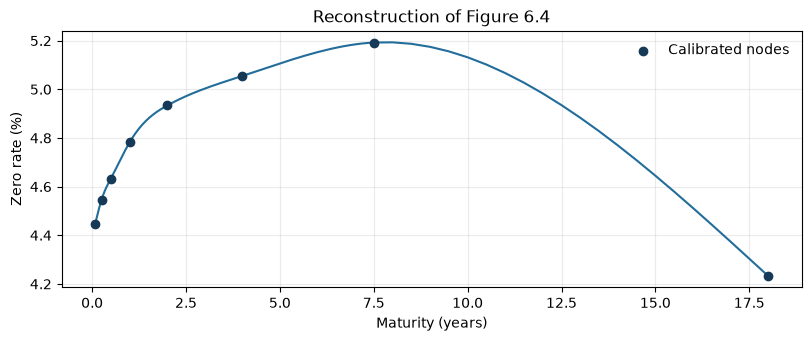

In [2]:
columns = [
    "variant", "maturity_years", "role", "fitted_rate_pct",
    "textbook_rate_pct", "rate_difference_bp", "input_price", "price_error",
]
formats = {
    "maturity_years": "{:.6f}",
    "fitted_rate_pct": "{:.8f}",
    "textbook_rate_pct": "{:.8f}",
    "rate_difference_bp": "{:+.4f}",
    "input_price": "{:.2f}",
    "price_error": "{:.3g}",
}

three_bonds = textbook.loc[textbook["example"].eq("table_6_1"), columns]
display(three_bonds.sort_values(["variant", "maturity_years"]).style.format(formats, na_rep="—").hide())

eight_bonds = textbook.loc[textbook["variant"].eq("one_month_1_over_12")]
eight_columns = [column for column in columns if column not in {"variant", "role"}]
display(eight_bonds[eight_columns].style.format(formats, na_rep="—").hide())
printed_short = textbook.loc[textbook["variant"].eq("printed_0_083")].iloc[0]
display(Markdown(f"最短期限直接取 0.083 年时，复算利率为 **{printed_short['fitted_rate_pct']:.4f}%**。"))

fig, ax = plt.subplots(figsize=(8, 3.3), layout="constrained")
ax.plot(book_curve["maturity_years"], book_curve["fitted_rate_pct"], color="#226D9A")
ax.scatter(eight_bonds["maturity_years"], eight_bonds["fitted_rate_pct"],
           color="#153956", label="Calibrated nodes", zorder=3)
ax.set(title="Reconstruction of Figure 6.4", xlabel="Maturity (years)", ylabel="Zero rate (%)")
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.show()

## 2 缺失期限实验

每种参考曲线生成 20 只模拟债券。两个报价密度都留出 2.5、5.5、8.5 年来测试，训练债券分别为 17 只和 11 只。两种方法各自校准节点。

- **训练最大价格残差**检查模型是否还原了输入价格。
- **留出价格 MAE**衡量对三只测试债券的平均绝对定价误差，按每 100 面值的金额计。
- **零息利率 RMSE**衡量拟合曲线相对参考曲线的差异，以基点（bp）计，在共同的 191 点网格上计算。

In [3]:
display(Markdown(f"**校准收敛 {metrics['converged'].sum()} / {len(metrics)} 组**"))
display(metrics.drop(columns="solver_message").style.format({
    "max_train_price_error": "{:.2e}",
    "holdout_price_mae": "{:.6f}",
    "zero_rate_rmse_bp": "{:.4f}",
}, na_rep="—").hide())

**校准收敛 12 / 12 组**

shape,density,method,train_count,holdout_count,converged,max_train_price_error,holdout_price_mae,zero_rate_rmse_bp
rising,dense,linear,17,3,True,1.64e-10,0.019540,0.3367
rising,dense,natural_cubic,17,3,True,1.64e-10,0.000161,0.0383
rising,sparse,linear,11,3,True,1.22e-10,0.019527,0.5585
rising,sparse,natural_cubic,11,3,True,1.22e-10,0.000544,0.0581
inverted,dense,linear,17,3,True,1.16e-11,0.020667,0.3369
inverted,dense,natural_cubic,17,3,True,1.16e-11,0.000167,0.0383
inverted,sparse,linear,11,3,True,5.07e-12,0.020654,0.5591
inverted,sparse,natural_cubic,11,3,True,5.07e-12,0.000581,0.0581
humped,dense,linear,17,3,True,1.72e-12,0.040822,1.0935
humped,dense,natural_cubic,17,3,True,1.69e-12,0.001016,0.1907


## 3 曲线和误差

先看驼峰曲线在稀疏报价下的拟合。三条线在整条曲线的尺度上很接近，因此下图组再画出每个期限的有符号误差。灰色竖线标记留出债券的到期期限。

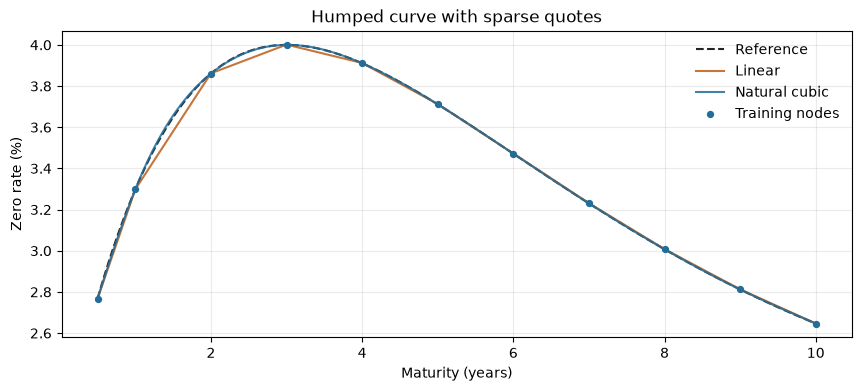

In [4]:
colors = {"linear": "#BC5D19", "natural_cubic": "#226D9A"}
labels = {"linear": "Linear", "natural_cubic": "Natural cubic"}

example = curves.query("shape == 'humped' and density == 'sparse'")
reference = example.query("method == 'linear'")
fig, ax = plt.subplots(figsize=(8.5, 3.8), layout="constrained")
ax.plot(reference["maturity_years"], reference["reference_rate"] * 100,
        color="#242424", linestyle="--", label="Reference")
for method, group in example.groupby("method", sort=False):
    ax.plot(group["maturity_years"], group["fitted_rate"] * 100,
            color=colors[method], label=labels[method], alpha=0.85)
nodes = example.query("method == 'natural_cubic' and is_training_node")
ax.scatter(nodes["maturity_years"], nodes["fitted_rate"] * 100, s=18,
           color=colors["natural_cubic"], label="Training nodes", zorder=4)
ax.set(title="Humped curve with sparse quotes", xlabel="Maturity (years)", ylabel="Zero rate (%)")
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.show()

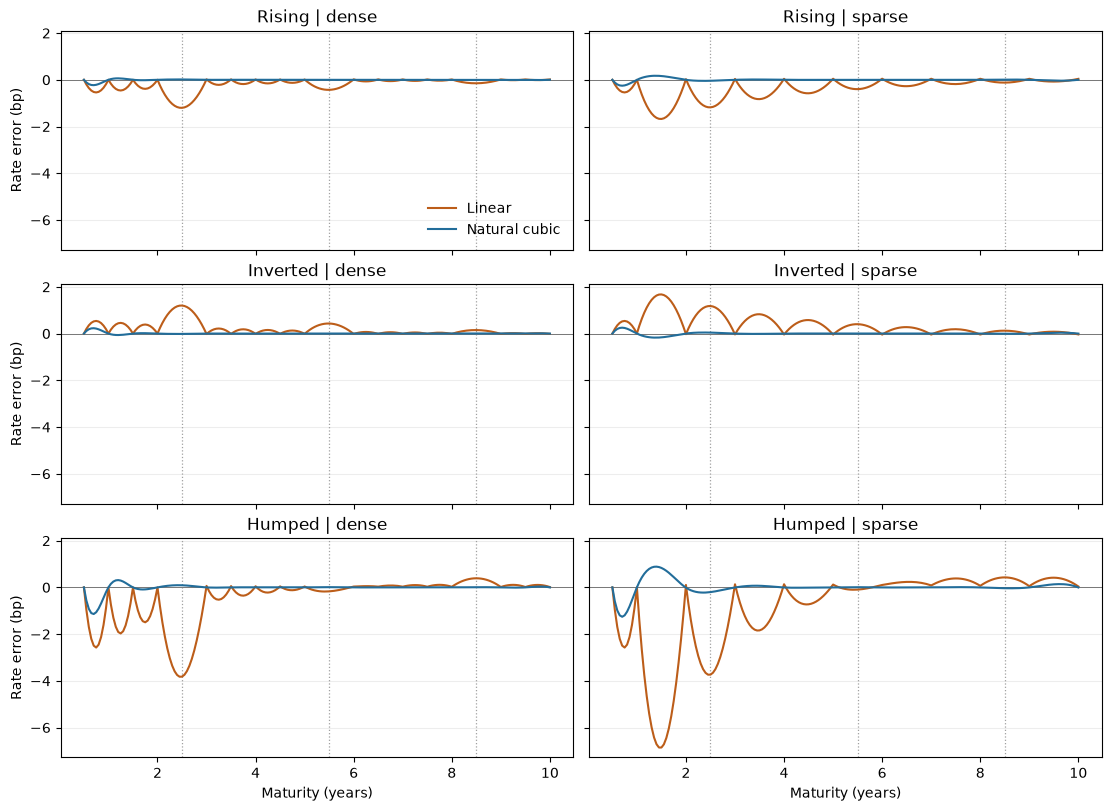

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True, sharey=True, layout="constrained")
test_terms = sorted(holdouts["maturity_years"].unique())
for row, shape in enumerate(("rising", "inverted", "humped")):
    for col, density in enumerate(("dense", "sparse")):
        ax = axes[row, col]
        section = curves.loc[curves["shape"].eq(shape) & curves["density"].eq(density)]
        for maturity in test_terms:
            ax.axvline(maturity, color="#a0a0a0", linestyle=":", linewidth=0.9)
        ax.axhline(0, color="#777777", linewidth=0.7)
        for method, group in section.groupby("method", sort=False):
            error = (group["fitted_rate"] - group["reference_rate"]) * 10_000
            ax.plot(group["maturity_years"], error, label=labels[method], color=colors[method])
        ax.set_title(f"{shape.capitalize()} | {density}")
        ax.grid(axis="y", alpha=0.22)
        if col == 0:
            ax.set_ylabel("Rate error (bp)")
        if row == 2:
            ax.set_xlabel("Maturity (years)")
axes[0, 0].legend(frameon=False, loc="lower right")
plt.show()

## 4 如何解读

利率 RMSE 衡量整个期限网格，留出 MAE 衡量三只测试债券。一只债券的不同现金流折现误差可以互相抵消，因此两个指标随报价密度变化时可能出现不同方向。本次比较适用于所设定的平滑参考曲线、固定留出期限和无噪声价格。

In [6]:
metric_columns = ["holdout_price_mae", "zero_rate_rmse_bp"]
pairs = metrics.pivot(index=["shape", "density"], columns="method", values=metric_columns).dropna()
price_errors = pairs["holdout_price_mae"]
rate_errors = pairs["zero_rate_rmse_bp"]
price_wins = (price_errors["natural_cubic"] < price_errors["linear"]).sum()
rate_wins = (rate_errors["natural_cubic"] < rate_errors["linear"]).sum()
display(Markdown(
    f"在 **{len(pairs)}** 个两种方法均成功的配对中，"
    f"样条的留出定价 MAE 较低的有 **{price_wins}** 个，"
    f"零息利率 RMSE 较低的有 **{rate_wins}** 个。"
))

humped_holdout = holdouts.query("shape == 'humped' and density == 'sparse'")
display(humped_holdout[["method", "maturity_years", "simulated_price", "fitted_price", "price_error"]]
        .style.format({"simulated_price": "{:.6f}", "fitted_price": "{:.6f}", "price_error": "{:+.6f}"},
                      na_rep="—").hide())

在 **6** 个两种方法均成功的配对中，样条的留出定价 MAE 较低的有 **6** 个，零息利率 RMSE 较低的有 **6** 个。

method,maturity_years,simulated_price,fitted_price,price_error
linear,2.500000,100.017610,100.105798,+0.088188
linear,5.500000,101.740963,101.750378,+0.009415
linear,8.500000,107.333911,107.309147,-0.024764
natural_cubic,2.500000,100.017610,100.022054,+0.004443
natural_cubic,5.500000,101.740963,101.740477,-0.000487
natural_cubic,8.500000,107.333911,107.336206,+0.002295
